In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize


In [2]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        
    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(self.start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(self.end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()
        self.read_tccon()

In [3]:
class inversion():
    def __init__(self,path,period,start_date, end_date,analysis_start_date, analysis_end_date,color,BG,BG_ds,correlations,g_err=2,i_err=2):
        self.path = path
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.analysis_start_date=analysis_start_date
        self.analysis_end_date=analysis_end_date
        self.correlations=correlations
        self.color=color
        self.BG=BG
        self.BG_ds=BG_ds
        self.data={}
        self.g_err=g_err
        self.i_err=i_err
    def read_data(self):
        for i in range(len(self.correlations)):
            self.data[self.correlations[i]]=data(self.path,self.period,self.analysis_start_date, self.analysis_end_date,self.BG,self.BG_ds,correlation=self.correlations[i],g_err=self.g_err,i_err=self.i_err)
            self.data[self.correlations[i]].read_data()
            self.data[self.correlations[i]].color=self.color[i]
    
                

In [4]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
            ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                               color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [5]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)

        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [6]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

In [7]:
# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=int((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [8]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2020,10,1), dt.date(2022,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/correlations/'

In [9]:
path='inversions_new/TM5_correlations/'
correlations=['no','spatial','temporal','temporal_1M','with','with_1M','with_e04']
BG='TM5'
BG_ds='RemoTeC_2.4.1+IS-land_ocean_bc'
inversion_TM5=inversion(path,period,start_date, end_date,analysis_start_date,analysis_end_date,color,BG,BG_ds,correlations,g_err=2,i_err=3)
inversion_TM5.read_data()

In [10]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

In [11]:
prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

# Zeitreihe

In [12]:
inversion=inversion_TM5
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        print([i,j])
        k=0
        for corr in inversion.correlations:
            temp=inversion.data[corr].fluxes.where(((inversion.data[corr].fluxes.latitude>= regions_lat[i]) &(inversion.data[corr].fluxes.latitude<regions_lat[i+1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
                      
            plt.plot(temp.time, temp.TM5_posterior_flux, c=inversion.data[corr].color, marker='o', markersize=2, label=f'{BG} posterior {corr} correlation')
            plt.fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color='blue', alpha=0.2)  
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[i]) &(TM54DVar_posterior_flux.latitude<regions_lat[i+1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6
        #temp3['prior_uncertainty']=temp3.prior_uncertainty*1e6
        plt.plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        plt.fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='orange', alpha=0.2) 

        plt.plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')
        #plt.fill_between(temp3.time, temp3.TM5_posterior_flux-temp2.TM5_posterior_std, temp2.TM5_posterior_flux+temp2.TM5_posterior_std, color='red', alpha=0.2) 
        plt.ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        plt.legend()
        plt.xticks(rotation=45)
        plt.title(f"{regions_lat[i]} to {regions_lat[i+1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        plt.tight_layout()
        #plt.show()
        #plt.savefig(f'{savefig}/fluxes{regions_lat[i]}-{regions_lat[i+1]}N_{regions_lon[j]}-{regions_lon[j+1]}E.png',bbox_inches='tight',transparent=True)
        plt.close()

<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_4151968/2774103703.py:29: SyntaxWarning: invalid escape sequence '\m'
  plt.ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


[0, 0]
[0, 1]
[0, 2]
[1, 0]
[1, 1]
[1, 2]


In [13]:
['no','spatial','temporal','temporal_1M','with','with_1M','with_e04']

['no', 'spatial', 'temporal', 'temporal_1M', 'with', 'with_1M', 'with_e04']

0
1
2
0


/tmp/ipykernel_2197625/2551587380.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


1


/tmp/ipykernel_2197625/2551587380.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


2


/tmp/ipykernel_2197625/2551587380.py:39: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


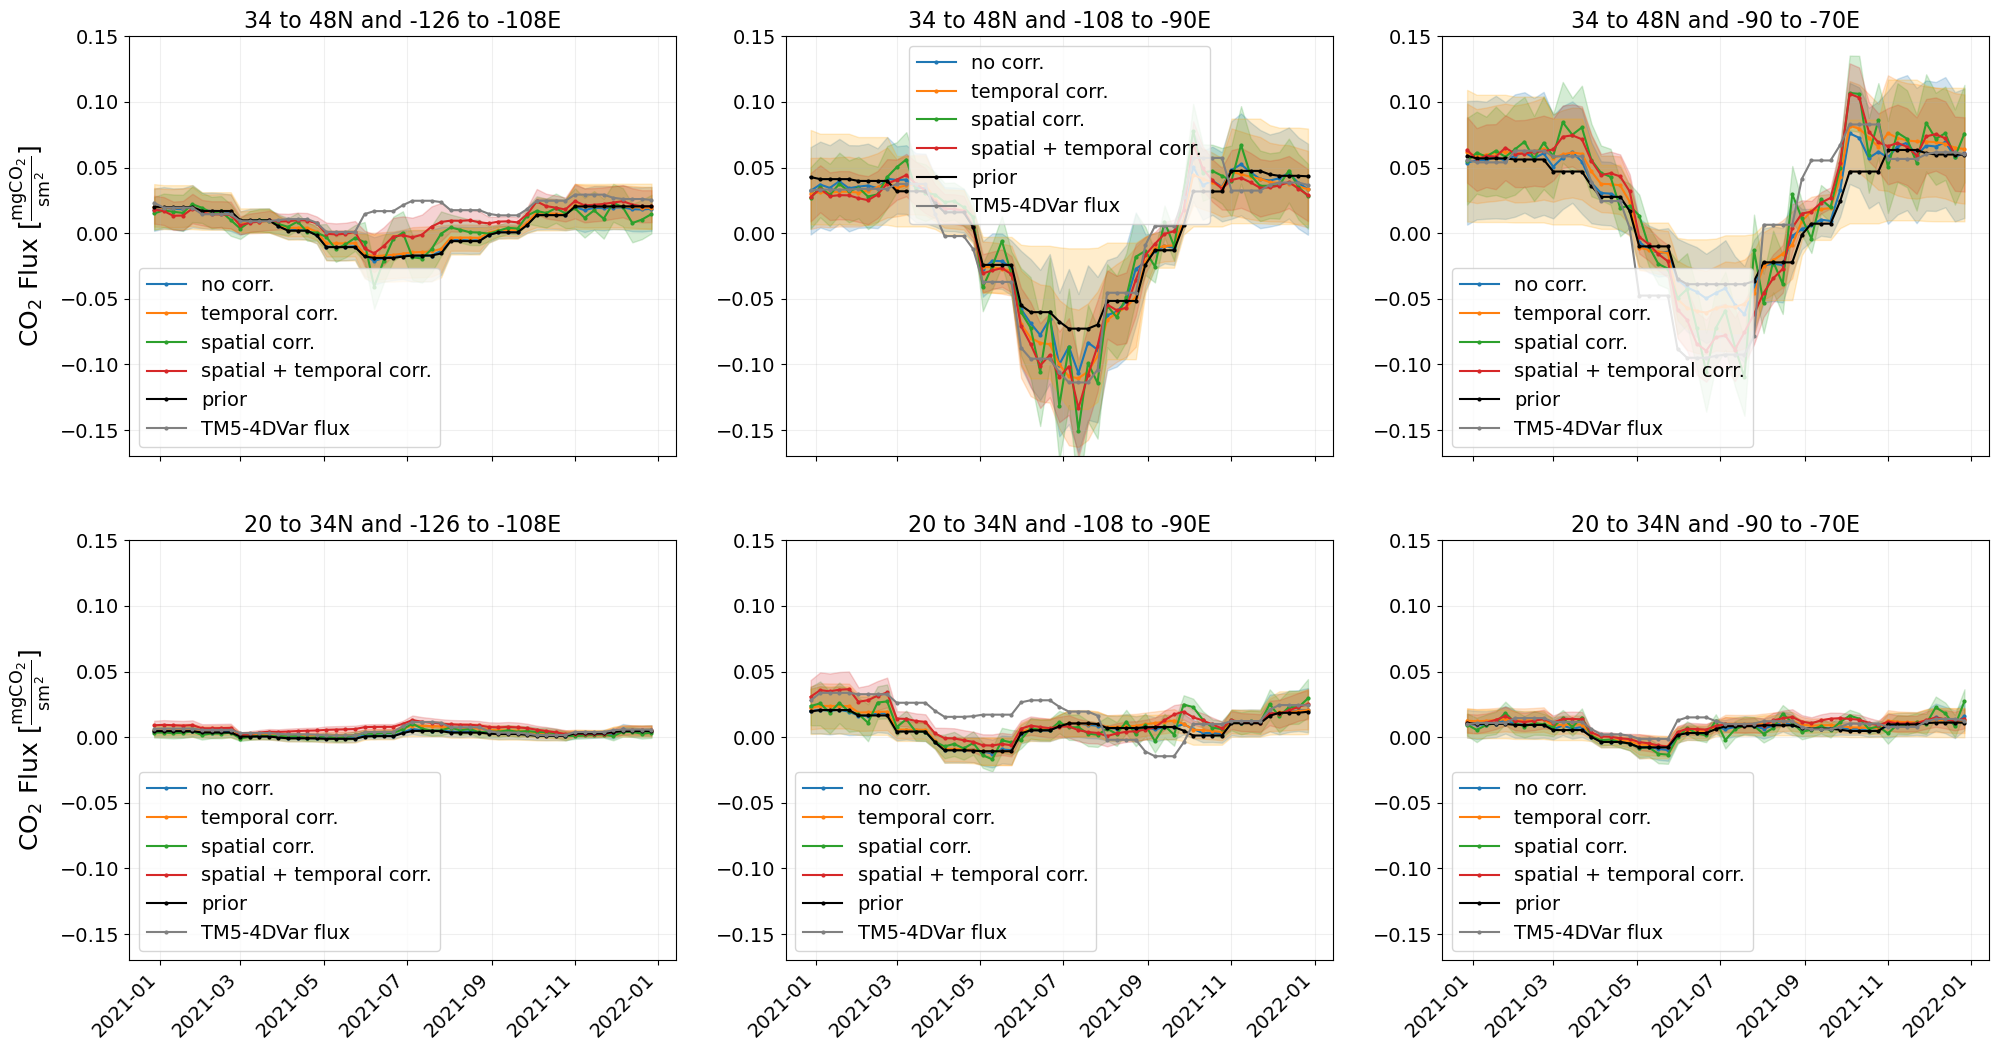

In [12]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
inversion=inversion_TM5
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label=['no','temporal','spatial','spatial + temporal']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        print(j)
        k=0
        for corr in ['no', 'temporal', 'spatial', 'with']:
            temp=inversion.data[corr].fluxes.where(((inversion.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inversion.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label[k]} corr.')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='orange', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        #axs[i,j].tight_layout()
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.savefig(f'{savefig}/no_spatial_temporal_with/regional_fluxes_some_corr_no_spatial_temporal.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
plt.show()

In [15]:
def plot_map_no_colorbar(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax,rasterized=True,add_colorbar=False) 
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 14}
    gl.ylabel_style = {'size': 14}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.set_title(label,fontsize=16)
    ax.set_aspect(aspect=1)
    return plot

/tmp/ipykernel_2197625/319978773.py:25: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


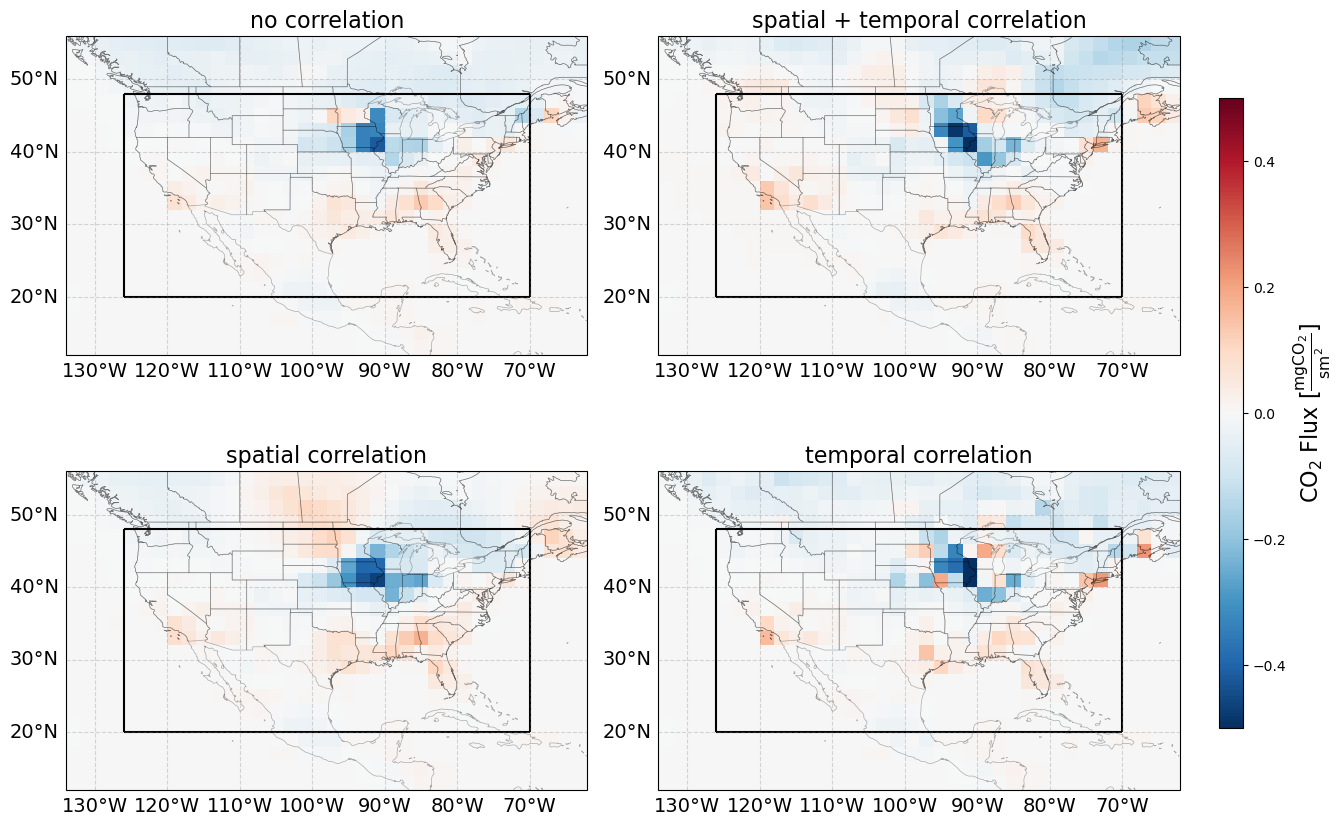

In [16]:
fig,axs=plt.subplots(2,2,figsize=(12,9), subplot_kw={'projection': ccrs.PlateCarree()})
vmin=0.5
date=dt.date(2021, 8, 16)
corr='no'
temp=inversion_TM5.data[corr].fluxes.TM5_posterior_flux
plot=plot_map_no_colorbar(temp.where(temp.time.dt.date==date,drop=True)*1e6,corr+' correlation',axs[0][0],vmin=-vmin,vmax=vmin)
corr='with'
temp=inversion_TM5.data[corr].fluxes.TM5_posterior_flux
plot=plot_map_no_colorbar(temp.where(temp.time.dt.date==date,drop=True)*1e6,'spatial + temporal'+' correlation',axs[0][1],vmin=-vmin,vmax=vmin)
corr='spatial'
temp=inversion_TM5.data[corr].fluxes.TM5_posterior_flux
plot=plot_map_no_colorbar(temp.where(temp.time.dt.date==date,drop=True)*1e6,corr+' correlation',axs[1][0],vmin=-vmin,vmax=vmin)
corr='temporal'
temp=inversion_TM5.data[corr].fluxes.TM5_posterior_flux
plot=plot_map_no_colorbar(temp.where(temp.time.dt.date==date,drop=True)*1e6,corr+' correlation',axs[1][1],vmin=-vmin,vmax=vmin)

# Reserve room on the right
fig.subplots_adjust(right=0.87)
# [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([1.02, 0.15, 0.02, 0.70])

cbar = fig.colorbar(plot, cax=cbar_ax)
cbar.set_label('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=16)

plt.tight_layout()
plt.savefig(savefig+f'/no_spatial_temporal_with/no_spatial_temporal_with_map{str(date)}.pdf', bbox_inches='tight',dpi=500)

/tmp/ipykernel_2197625/3449500325.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


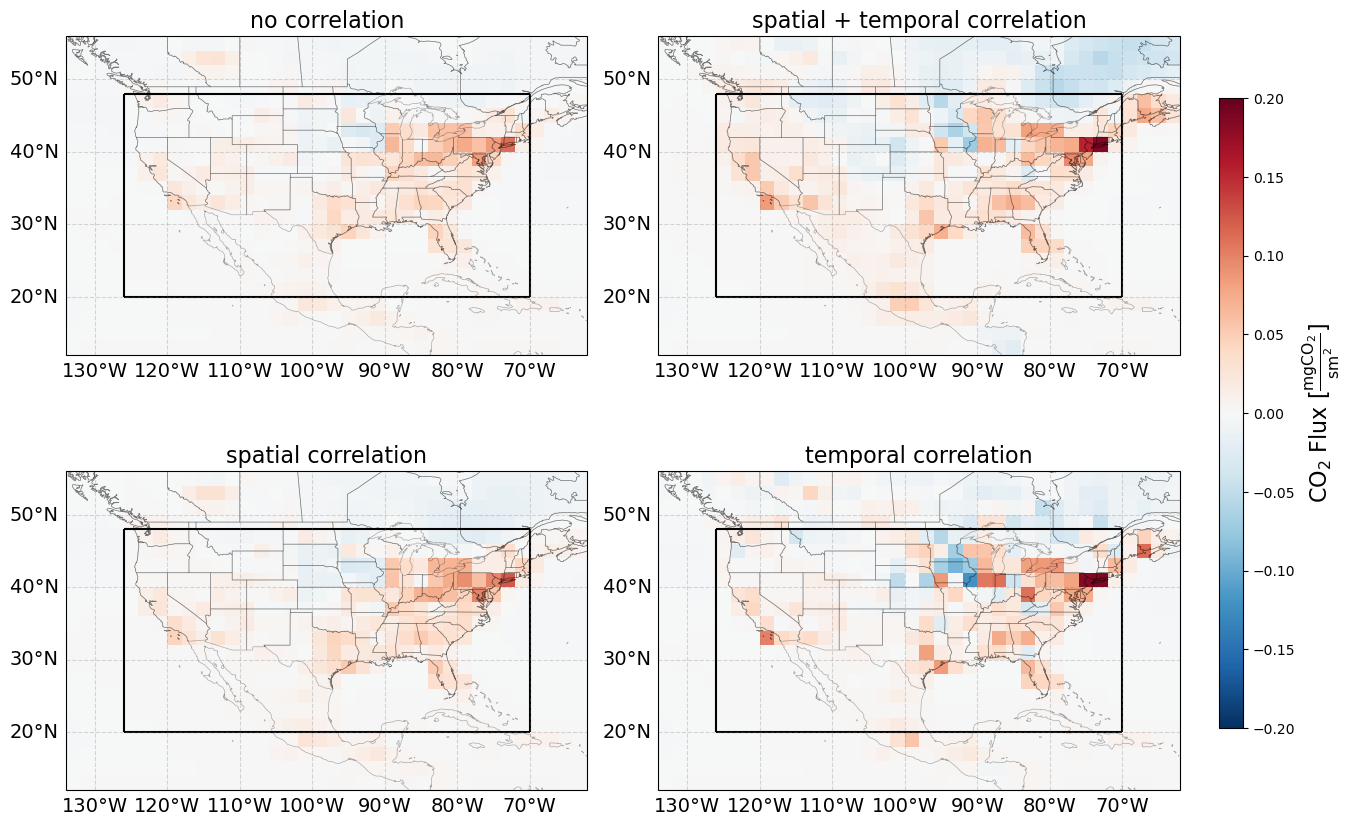

In [17]:
corr='no'
fig,axs=plt.subplots(2,2,figsize=(12,9), subplot_kw={'projection': ccrs.PlateCarree()})
vmin=0.2
corr='no'
plot=plot_map_no_colorbar(inversion_TM5.data[corr].fluxes.TM5_posterior_flux.mean('time')*1e6,corr+' correlation',axs[0][0],vmin=-vmin,vmax=vmin)
corr='with'
plot=plot_map_no_colorbar(inversion_TM5.data[corr].fluxes.TM5_posterior_flux.mean('time')*1e6,'spatial + temporal'+' correlation',axs[0][1],vmin=-vmin,vmax=vmin)
corr='spatial'
plot=plot_map_no_colorbar(inversion_TM5.data[corr].fluxes.TM5_posterior_flux.mean('time')*1e6,corr+' correlation',axs[1][0],vmin=-vmin,vmax=vmin)
corr='temporal'
plot=plot_map_no_colorbar(inversion_TM5.data[corr].fluxes.TM5_posterior_flux.mean('time')*1e6,corr+' correlation',axs[1][1],vmin=-vmin,vmax=vmin)

# Reserve room on the right
fig.subplots_adjust(right=0.87)
# [left, bottom, width, height] in figure coordinates
cbar_ax = fig.add_axes([1.02, 0.15, 0.02, 0.70])

cbar = fig.colorbar(plot, cax=cbar_ax)
cbar.set_label('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]', fontsize=16)

plt.tight_layout()
plt.savefig(savefig+'/no_spatial_temporal_with/no_spatial_temporal_with_map_2021.pdf', bbox_inches='tight',dpi=500)

In [18]:
prior_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/2ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

colors=['black','grey']
marker=['x','x']
k=0
path='inversions_new/TM5_correlations/'
label=['no','temporal','spatial','spatial + temporal']
for corr in ['no','temporal','spatial','with']:
    datasets_dir.append(f'{path}/2x2/{corr}_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc')
    labels.append(f'{label[k]}')
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')

print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'no, spatial, temporal and spatial & temporal correlation', start_date, end_date,savefig+'no_spatial_temporal_with_corr_'+'2x2.png')


['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std', 'TM5_posterior_std']
['black', 'grey', '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
['x', 'x', 'o', 'o', 'o', 'o']
saved to: figures_2/correlations/no_spatial_temporal_with_corr_2x2.png


In [15]:
temp.TM5_averaging_kernel_diag

<xarray.DataArray 'TM5_averaging_kernel_diag' (time: 53)> Size: 424B
array([3.83004886e-03, 2.90889427e-03, 1.16607286e-03, 1.46291028e-03,
       2.47160818e-02, 2.18158174e-03, 8.04392316e-04, 2.09717730e-02,
       1.63114763e-03, 1.76153419e-04, 5.73096626e-05, 3.31747508e-05,
       1.86225987e-04, 2.41775123e-03, 7.56433313e-03, 2.08138510e-04,
       2.14406558e-03, 2.03557116e-02, 3.39179885e-03, 2.01492041e-03,
       2.07276810e-04, 6.53390812e-03, 2.72417868e-04, 1.17507469e-03,
       2.73976170e-04, 6.22815966e-05, 1.41113666e-04, 3.71473426e-04,
       2.72088415e-03, 4.42133138e-03, 6.66372846e-04, 6.65674465e-03,
       1.57622911e-03, 3.93271380e-03, 2.25746252e-03, 2.54696024e-03,
       1.27849703e-02, 4.30391159e-03, 1.67938267e-02, 2.90297257e-03,
       4.50865433e-03, 1.05109522e-02, 3.27732947e-03, 3.98871246e-02,
       3.54696602e-02, 1.47395231e-01, 2.51763482e-02, 4.50404617e-03,
       2.14724392e-01, 7.36165554e-01, 1.96742922e-02, 1.18025076e-01,
       3.76682675e-02])
Coordinates:
  * time       (time) datetime64[ns] 424B 2020-12-28 2021-01-04 ... 2021-12-27
    latitude   float32 4B 31.0
    longitude  float32 4B -99.0
    height     float32 4B 30.0
Attributes:
    units:    kgCO2/(m^2 s)

<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_950279/1130031354.py:33: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
/tmp/ipykernel_950279/1130031354.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


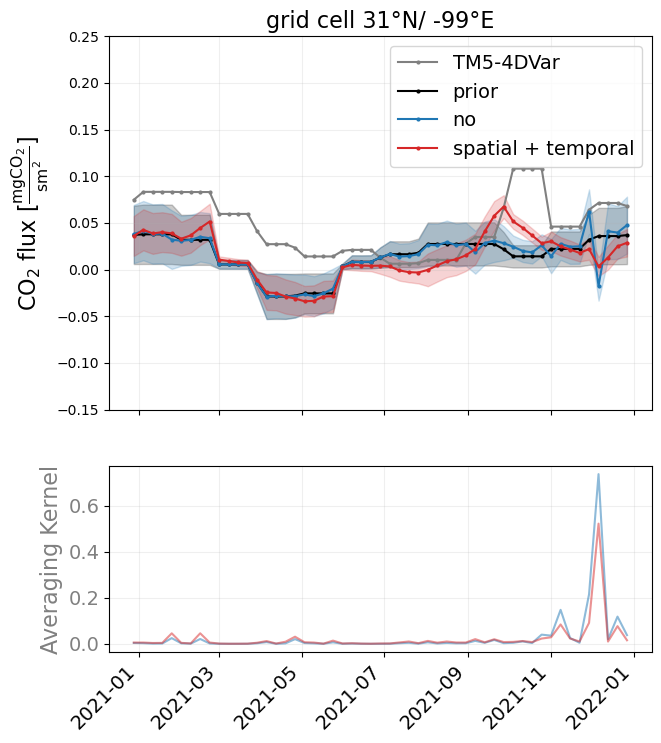

/tmp/ipykernel_950279/1130031354.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


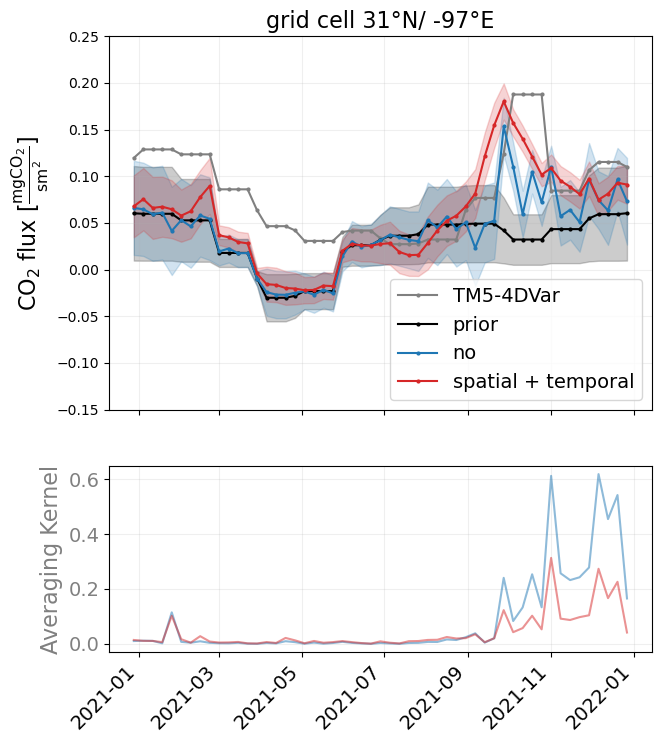

/tmp/ipykernel_950279/1130031354.py:40: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


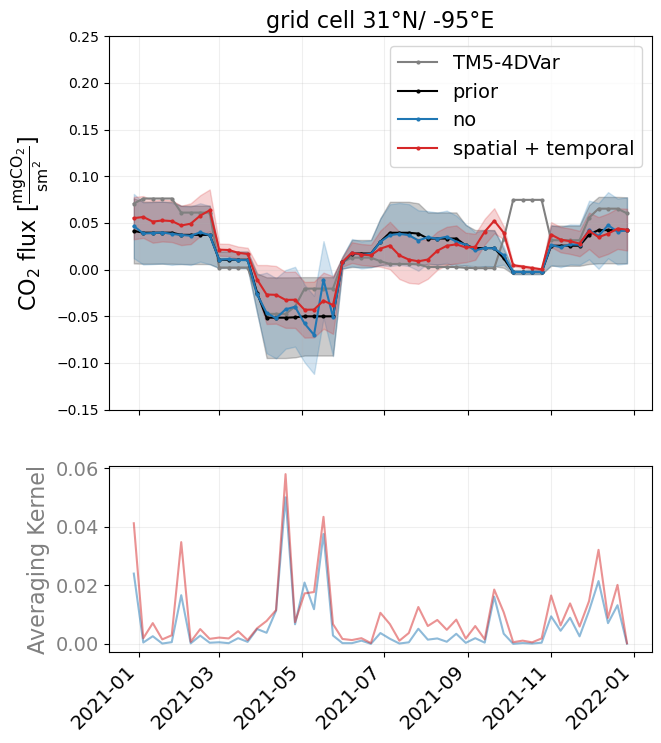

In [32]:
min,max=-0.15,0.25
lat_lon=[(31,-99),(31,-97),(31,-95)]
for lat,lon in lat_lon:
    fig,axs=plt.subplots(2,1,figsize=(7,8),gridspec_kw={'height_ratios': [2, 1]})
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp3=TM54DVar_posterior_flux.sel(latitude=lat,longitude=lon)
    temp3['total_flux']=temp3.total_flux*1e6
    axs[0].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')
    k=0
    label=['no','spatial + temporal']

    temp=inversion_TM5.data['no'].fluxes.sel(latitude=lat,longitude=lon)
    temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
    temp['prior_uncertainty']=temp.prior_uncertainty*1e6
    temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
    temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
    if k==0:
        axs[0].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[0].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2) 
    axs[0].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[0], marker='o', markersize=2, label=f'{label[0]}')
    axs[0].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[0], alpha=0.2) 
    axs[1].plot(temp.time, temp.TM5_averaging_kernel_diag, color=default_colors[0], alpha=0.5)  

    temp=inversion_TM5.data['with'].fluxes.sel(latitude=lat,longitude=lon)
    temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
    temp['prior_uncertainty']=temp.prior_uncertainty*1e6
    temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
    temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
    axs[0].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[3], marker='o', markersize=2, label=f'{label[1]}')
    axs[0].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[3], alpha=0.2)   
    axs[1].plot(temp.time, temp.TM5_averaging_kernel_diag, color=default_colors[3], alpha=0.5)

    axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
    axs[0].legend(fontsize=14)
    axs[0].set_ylim(min,max)

    axs[0].tick_params(axis='x',labelbottom=False)
    axs[1].tick_params(axis='x', labelrotation=45,labelsize =14)
    plt.yticks(fontsize=14)
    axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')

    axs[0].grid(visible=True, which='major', axis='both', alpha=0.2)
    axs[1].grid(visible=True, which='major', axis='both', alpha=0.2)

    color = 'tab:blue'
    axs[1].set_ylabel('Averaging Kernel', color='gray',fontsize=16)  # we already handled the x-label with ax1
    axs[1].tick_params(axis='y', labelcolor='gray')
    #axs[1].set_ylim(0,0.5)


    axs[0].set_title(f"grid cell {lat}°N/ {lon}°E",fontsize=16)
            #axs[i,j].tight_layout()
    #plt.savefig(f'{savefig}/no_spatial_temporal_with/no_with_girdbox_{lat}lat_{lon}lon_averaging_kernel.png',bbox_inches='tight',dpi=500)#,transparent=True)
    plt.show()


<>:26: SyntaxWarning: invalid escape sequence '\m'
<>:26: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_2197625/1335224146.py:26: SyntaxWarning: invalid escape sequence '\m'
  axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
/tmp/ipykernel_2197625/1335224146.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


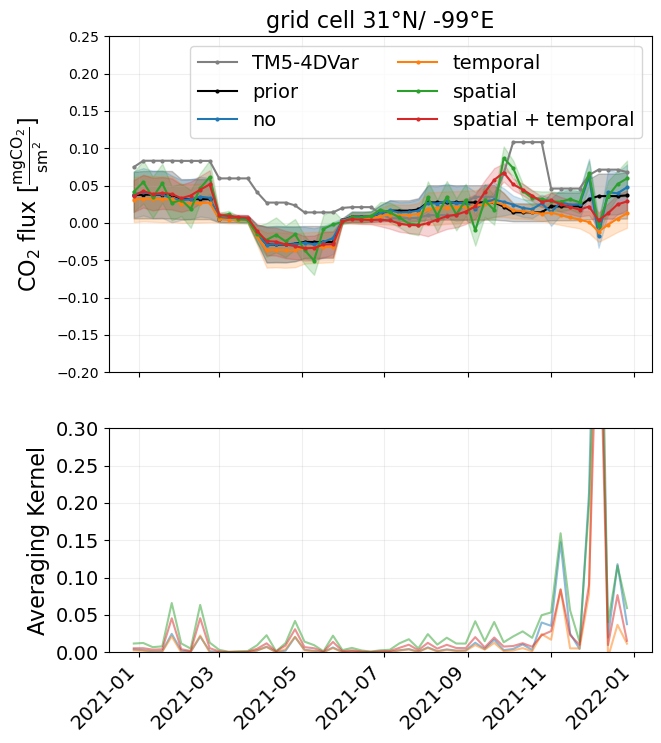

/tmp/ipykernel_2197625/1335224146.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


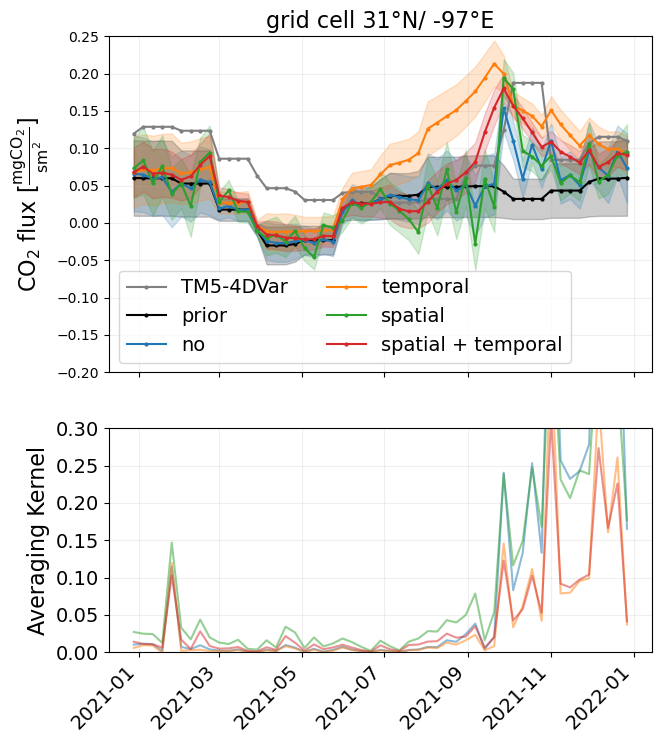

/tmp/ipykernel_2197625/1335224146.py:33: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')


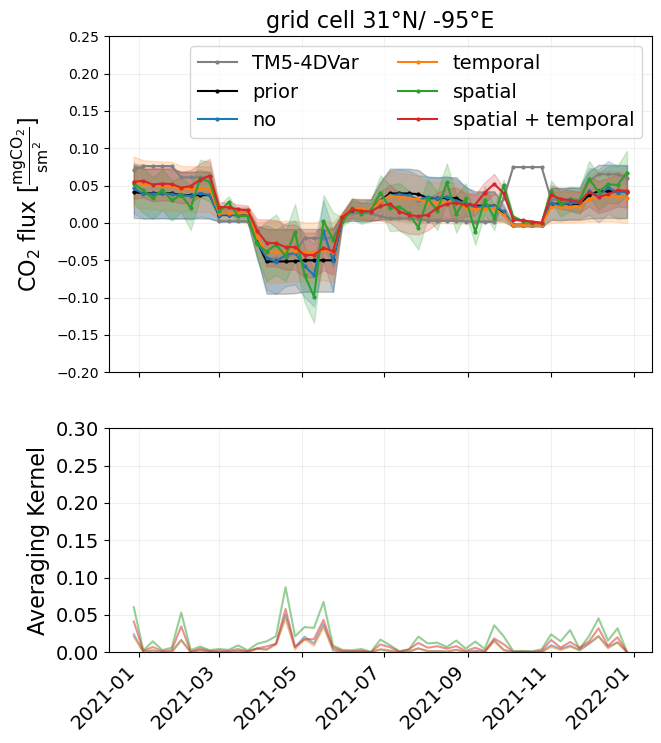

In [18]:
min,max=-0.2,0.25
lat_lon=[(31,-99),(31,-97),(31,-95)]
for lat,lon in lat_lon:
    fig,axs=plt.subplots(2,1,figsize=(7,8),gridspec_kw={'height_ratios': [3, 2]})
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp3=TM54DVar_posterior_flux.sel(latitude=lat,longitude=lon)
    temp3['total_flux']=temp3.total_flux*1e6
    axs[0].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')
    k=0
    label=['no','temporal','spatial','spatial + temporal']
    for corr in ['no','temporal','spatial','with']:
        temp=inversion_TM5.data[corr].fluxes.sel(latitude=lat,longitude=lon)
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        if k==0:
            axs[0].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
            axs[0].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2) 
        axs[0].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label[k]}')
        axs[0].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
        axs[1].plot(temp.time, temp.TM5_averaging_kernel_diag, color=default_colors[k], alpha=0.5)
        k+=1
    

    axs[0].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
    axs[0].legend(ncols=2,fontsize=14)
    axs[0].set_ylim(min,max)

    axs[0].tick_params(axis='x',labelbottom=False)
    axs[1].tick_params(axis='x', labelrotation=45,labelsize =14)
    plt.yticks(fontsize=14)
    axs[1].set_xticklabels((axs[1].get_xticklabels()),ha='right')

    axs[0].grid(visible=True, which='major', axis='both', alpha=0.2)
    axs[1].grid(visible=True, which='major', axis='both', alpha=0.2)

    axs[1].set_ylabel('Averaging Kernel',fontsize=16)  # we already handled the x-label with ax1
    axs[1].tick_params(axis='y')
    axs[0].set_title(f"grid cell {lat}°N/ {lon}°E",fontsize=16)
    axs[1].set_ylim(0,0.3)
            #axs[i,j].tight_layout()
    plt.savefig(f'{savefig}/no_spatial_temporal_with/no_spatial_temporal_with_girdbox_{lat}lat_{lon}lon_averaging_kernel.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
    plt.show()

<>:24: SyntaxWarning: invalid escape sequence '\m'
<>:24: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_1139965/2298260181.py:24: SyntaxWarning: invalid escape sequence '\m'
  axs.set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
/tmp/ipykernel_1139965/2298260181.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_xticklabels((axs.get_xticklabels()),ha='right')


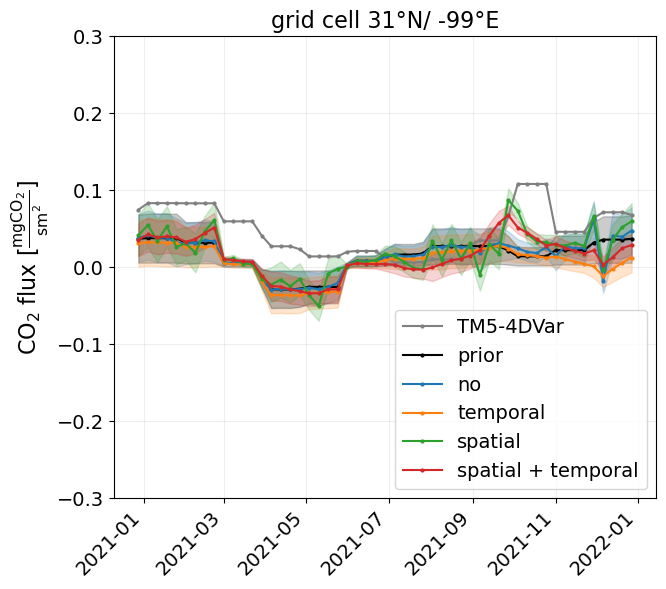

/tmp/ipykernel_1139965/2298260181.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_xticklabels((axs.get_xticklabels()),ha='right')


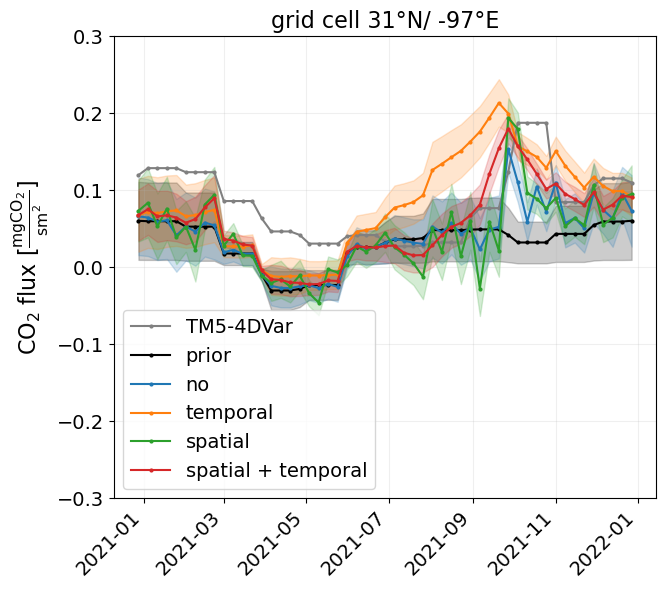

/tmp/ipykernel_1139965/2298260181.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs.set_xticklabels((axs.get_xticklabels()),ha='right')


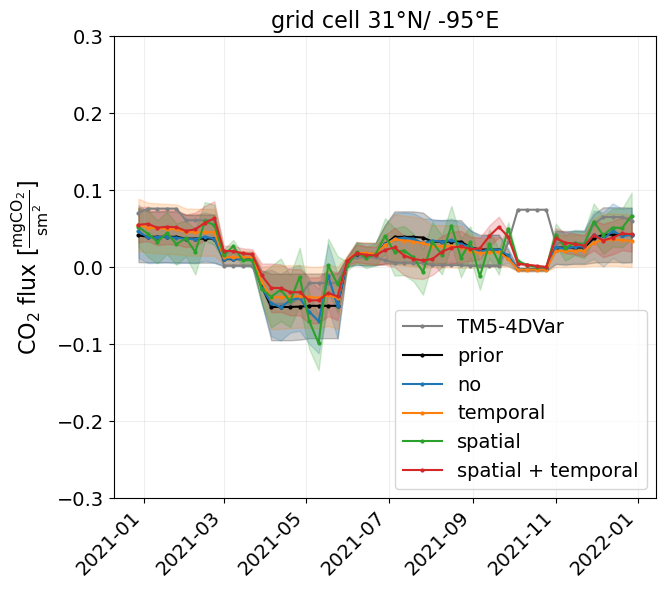

In [ ]:
min,max=-0.3,0.3
lat_lon=[(31,-99),(31,-97),(31,-95)]
for lat,lon in lat_lon:
    fig,axs=plt.subplots(1,1,figsize=(7,6))
    default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
    temp3=TM54DVar_posterior_flux.sel(latitude=lat,longitude=lon)
    temp3['total_flux']=temp3.total_flux*1e6
    axs.plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar')
    k=0
    label=['no','temporal','spatial','spatial + temporal']
    for corr in ['no','temporal','spatial','with']:
        temp=inversion_TM5.data[corr].fluxes.sel(latitude=lat,longitude=lon)
        temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
        temp['prior_uncertainty']=temp.prior_uncertainty*1e6
        temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
        temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
        if k==0:
            axs.plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
            axs.fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2) 
        axs.plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label[k]}')
        axs.fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
        k+=1

    axs.set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=16)
    axs.legend(fontsize=14)
    axs.set_ylim(min,max)
    axs.tick_params(axis='x', labelrotation=45,labelsize =14)
    plt.yticks(fontsize=14)
    axs.set_xticklabels((axs.get_xticklabels()),ha='right')

    axs.grid(visible=True, which='major', axis='both', alpha=0.2)
    axs.set_title(f"grid cell {lat}°N/ {lon}°E",fontsize=16)
            #axs[i,j].tight_layout()
    plt.savefig(f'{savefig}/no_spatial_temporal_with/no_spatial_temporal_with_girdbox_{lat}lat_{lon}lon.png',bbox_inches='tight',dpi=500)#,transparent=True)
    plt.show()


/tmp/ipykernel_2197625/2032695567.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2197625/2032695567.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2197625/2032695567.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


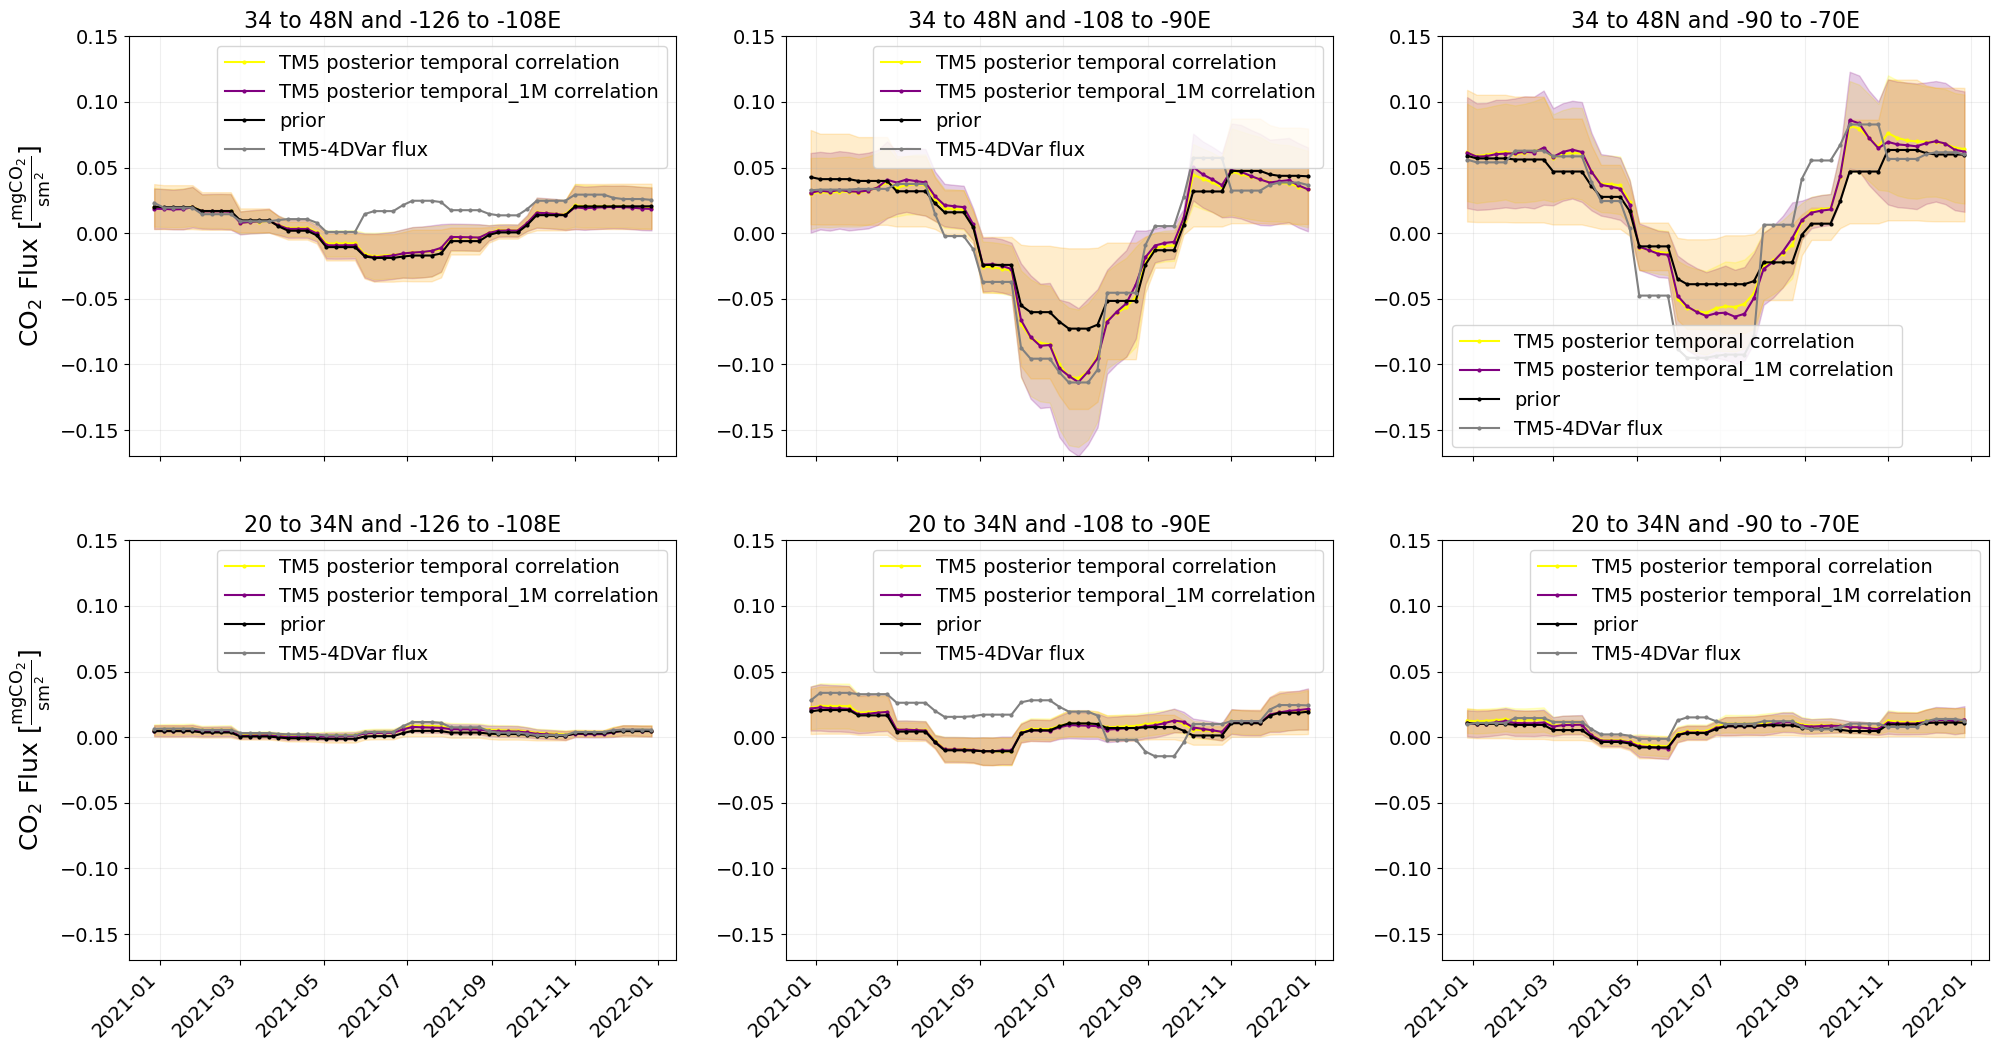

In [19]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
inversion=inversion_TM5

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        for corr in ['temporal','temporal_1M']:
            temp=inversion.data[corr].fluxes.where(((inversion.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inversion.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=inversion.data[corr].color, marker='o', markersize=2, label=f'{BG} posterior {corr} correlation')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=inversion.data[corr].color, alpha=0.2) 


        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='orange', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.savefig(f'{savefig}/temporal/regional_fluxes_some_corr_temporal.pdf',bbox_inches='tight')#,transparent=True)
plt.show()

In [22]:
prior_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/2ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

colors=['black','grey']
marker=['x','x']
k=0
path='inversions_new/TM5_correlations/'
label=['spatial + temporal T = 1 M','spatial + temporal T = 3 M']
for corr in ['with_1M','with']:
    datasets_dir.append(f'{path}/2x2/{corr}_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc')
    labels.append(f'{label[k]}')
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')

print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'spatial and temporal T = 1 M; T = 3 M', start_date, end_date,savefig+'/temporal/'+'spatial+temporal_1M_3M_'+'2x2.png')
 

['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std']
['black', 'grey', '#1f77b4', '#ff7f0e']
['x', 'x', 'o', 'o']
saved to: figures_2/correlations//temporal/spatial+temporal_1M_3M_2x2.png


In [23]:
inversion_TM5.data

{'no': <__main__.data at 0x7fec6fa108c0>,
 'spatial': <__main__.data at 0x7fec6dd02c30>,
 'temporal': <__main__.data at 0x7fec6d8cba10>,
 'temporal_1M': <__main__.data at 0x7fec6d8e8650>,
 'with': <__main__.data at 0x7fec6a263080>,
 'with_1M': <__main__.data at 0x7fec6d892d80>,
 'with_e04': <__main__.data at 0x7fec6a2e3f50>}

/tmp/ipykernel_2197625/3981497152.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2197625/3981497152.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_2197625/3981497152.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


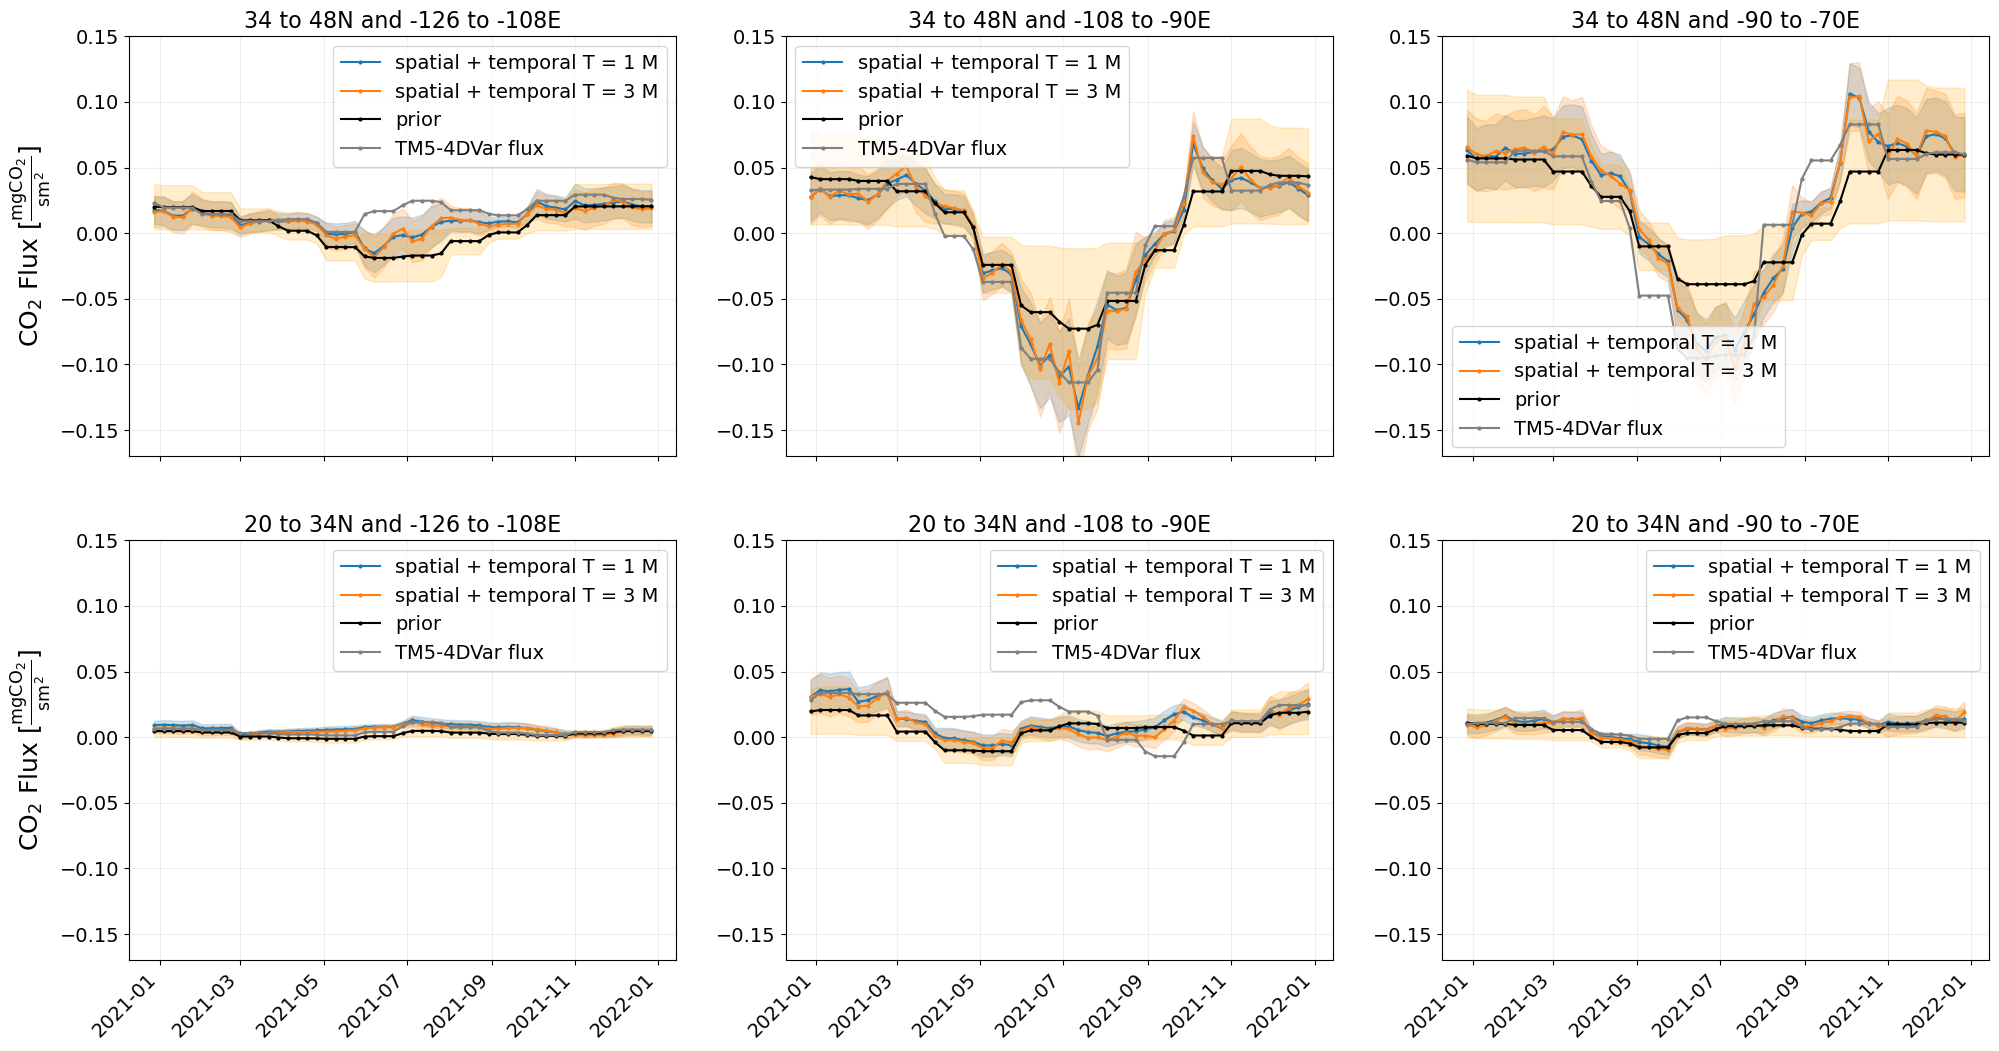

In [20]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
inversion=inversion_TM5
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label=['spatial + temporal T = 1 M','spatial + temporal T = 3 M']

for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        k=0
        for corr in ['with','with_1M']:
            temp=inversion.data[corr].fluxes.where(((inversion.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inversion.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label[k]}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='orange', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
        #axs[i,j].tight_layout()
plt.savefig(f'{savefig}/temporal/regional_fluxes_some_corr_w_w1.pdf',bbox_inches='tight',dpi=500)#,transparent=True)
plt.show()

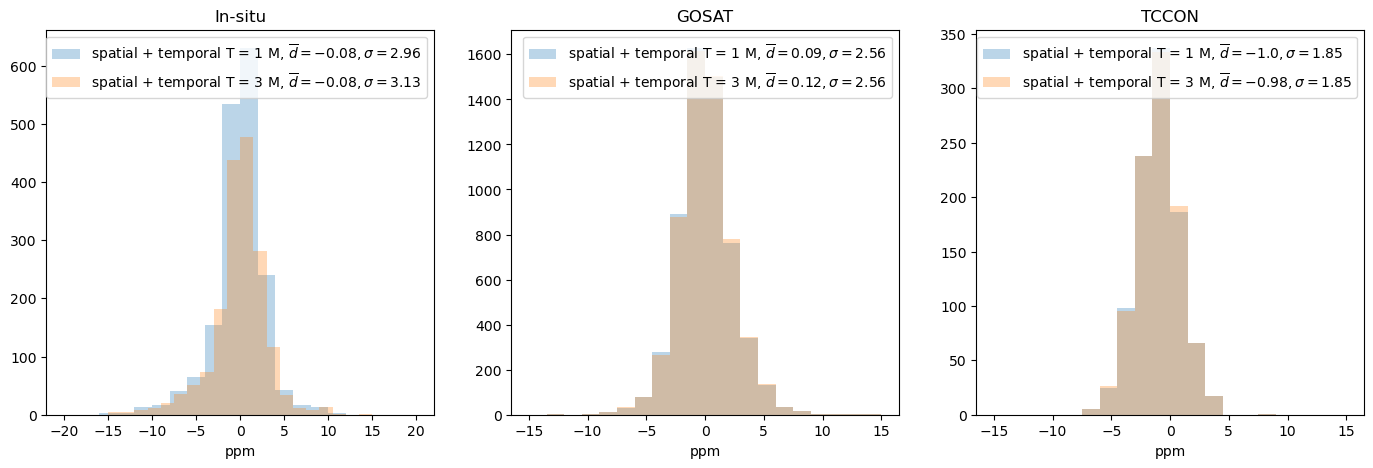

In [ ]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_corr=['spatial + temporal T = 1 M','spatial + temporal T = 3 M']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

k=0
for corr in ['with_1M', 'with']:
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    temp=inversion_TM5.data[corr].insitu
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_corr[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    axs[0].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=inversion_TM5.data[corr].gosat
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_corr[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    axs[1].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=inversion_TM5.data[corr].tccon
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_corr[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    axs[2].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])
    k+=1

plt.savefig(f'{savefig}/temporal/histogramm_with_1M_3M.png')

In [ ]:
inversion_TM5.data['with'].fluxes.TM5_posterior_flux

In [17]:
diff=(inversion_TM5.data['with'].fluxes.TM5_posterior_flux-inversion_TM5.data['with_1M'].fluxes.TM5_posterior_flux)
print('difference with, with_1M')
print(f'sum: {np.sum(diff.values)}')
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')
print('per standard deviation')
diff=(np.abs(inversion_TM5.data['with'].fluxes.TM5_posterior_flux-inversion_TM5.data['with_1M'].fluxes.TM5_posterior_flux))/inversion_TM5.data['with'].fluxes.TM5_posterior_std
print(f'max: {np.max(diff.values)}')
print(f'min: {np.min(diff.values)}')
print(f'mean: {np.mean(diff.values)}')

difference with, with_1M
sum: 3.248193009266525e-06
max: 1.5345242712019395e-07
min: -1.6929799401512953e-07
mean: 7.73821471618669e-11
per standard deviation
max: 4.567850219664798
min: 5.474266132720696e-05
mean: 0.33412162710506543


<>:4: SyntaxWarning: invalid escape sequence '\e'
<>:4: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_1139965/4176675878.py:4: SyntaxWarning: invalid escape sequence '\e'
  label_corr=[fr'spatial + temporal $\epsilon = 0.84$','spatial + temporal $\epsilon = 0.4$']
/tmp/ipykernel_1139965/4176675878.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_1139965/4176675878.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
/tmp/ipykernel_1139965/4176675878.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')


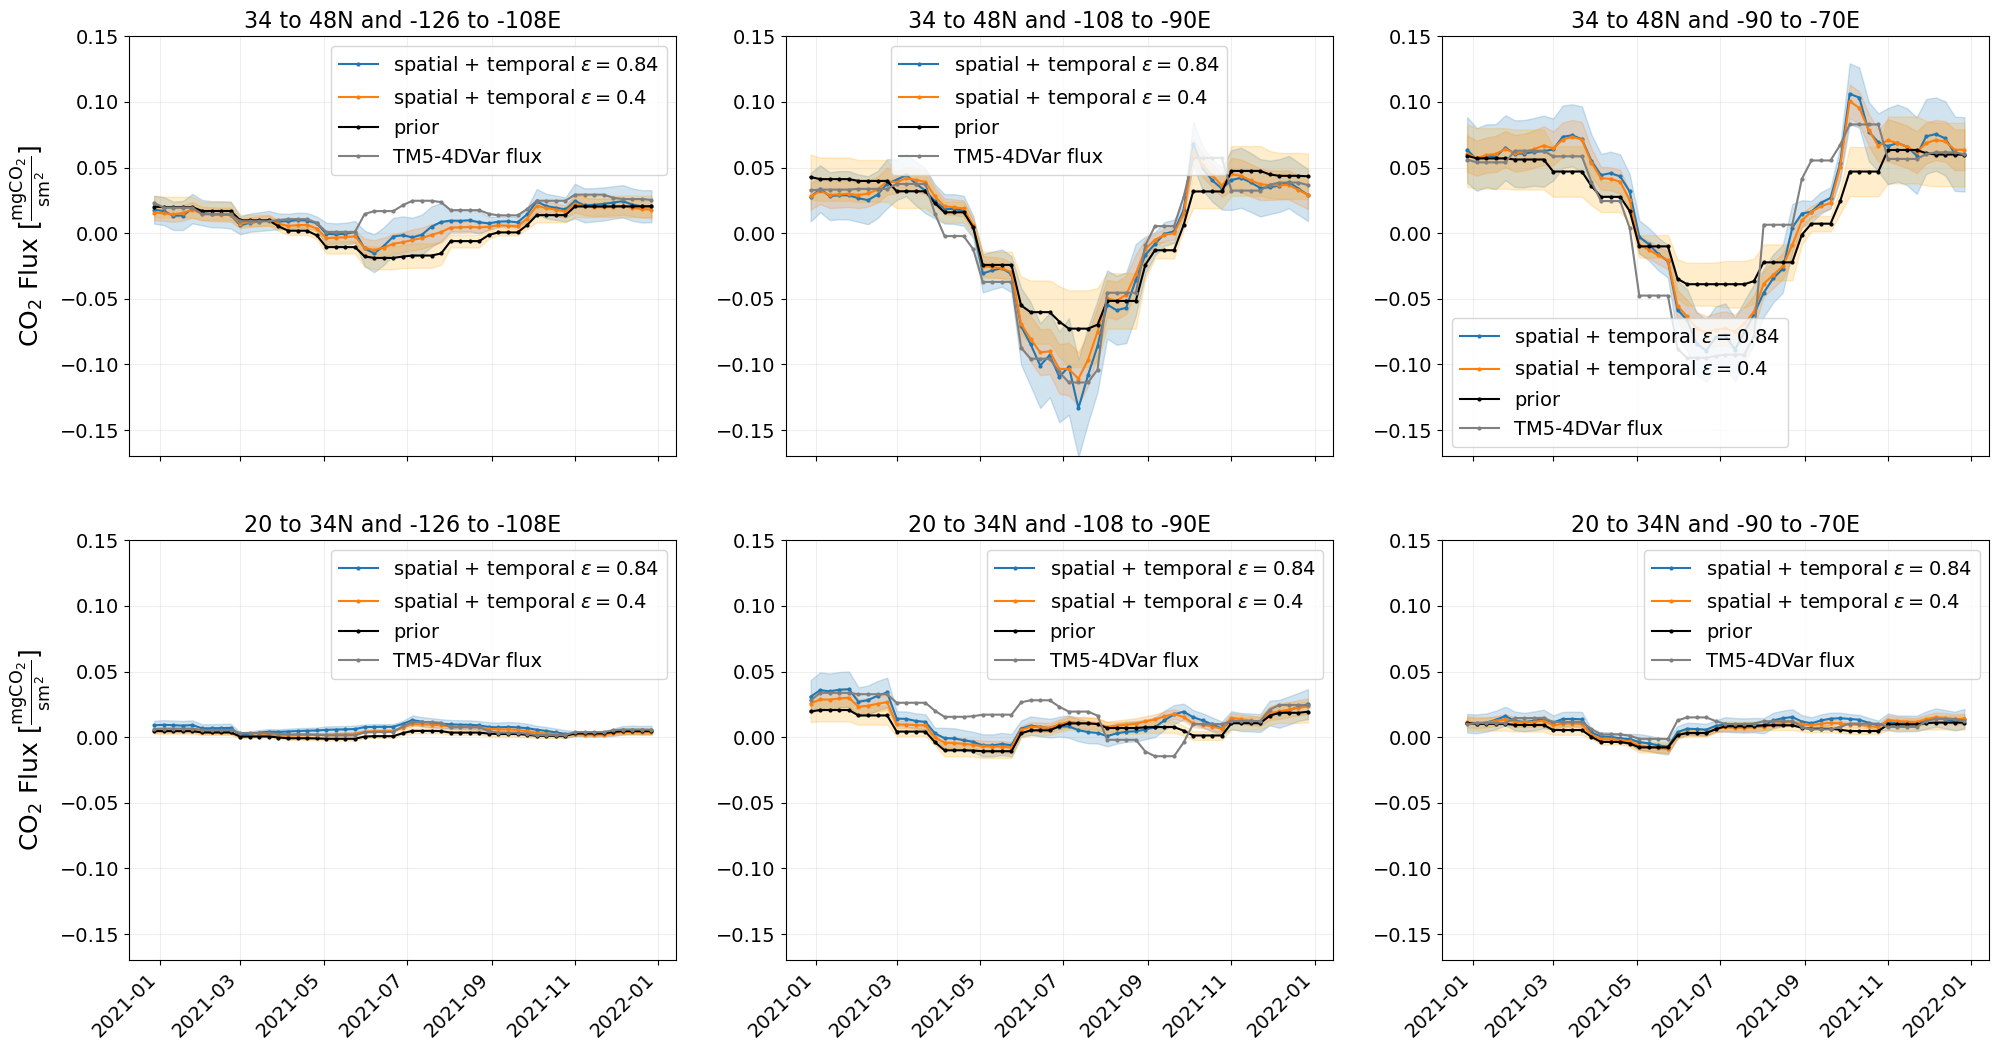

: 

In [15]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
inversion=inversion_TM5
label_corr=[fr'spatial + temporal $\epsilon = 0.84$','spatial + temporal $\epsilon = 0.4$']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

k=0
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        k=0
        for corr in ['with','with_e04']:
            temp=inversion.data[corr].fluxes.where(((inversion.data[corr].fluxes.latitude>= regions_lat[-i-2]) &(inversion.data[corr].fluxes.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label_corr[k]}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='orange', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')
        if j==0:
            axs[i,j].set_ylabel('CO$_2$ Flux [$\\mathrm{\\frac{mgCO_2}{s m^2}}$]',fontsize=18)        
        axs[i,j].legend(fontsize=14)
        axs[i,j].set_ylim(-0.17,0.15)
        if i==1:
            axs[i,j].tick_params(axis='x', labelrotation=45,labelsize =14)
            axs[i,j].set_xticklabels((axs[i,j].get_xticklabels()),ha='right')
        else:
            axs[i,j].tick_params(labelbottom=False)                   
        axs[i,j].tick_params(axis='y', labelsize =14)
        axs[i,j].grid(visible=True, which='major', axis='both', alpha=0.2)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E",fontsize=16)
plt.savefig(f'{savefig}/regional_fluxes_some_corr_w_we04.png',bbox_inches='tight')#,transparent=True)
plt.show()

In [27]:
inversion_TM5.i_err

3

In [28]:
prior_path=f'{path}/2x2/with_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/2ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc'
posterior_path='/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc'
datasets_dir=[prior_path,posterior_path]
parameters=['TM5_prior_flux','total_flux']
parameters_uncertainty=['prior_uncertainty', False]
labels=['prior','TM5-4DVar']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

colors=['black','grey']
marker=['x','x']
k=0
path='inversions_new/TM5_correlations/'
label=[fr'spatial + temporal $\epsilon = 0.4$','spatial + temporal $\epsilon = 0.84$']
for corr in ['with_e04','with']:
    datasets_dir.append(f'{path}/2x2/{corr}_correlation/footprint_spec001_mr/2ppm_gosat_meas_err/3ppm_insitu_meas_err/{period}_{BG_ds}_bg.nc')
    labels.append(f'{label[k]}')
    parameters.append(f'TM5_posterior_flux')
    parameters_uncertainty.append('TM5_posterior_std')
    colors.append(default_colors[k])
    k+=1
    marker.append('o')

print(parameters)
print(parameters_uncertainty)
print(colors)
print(marker)
plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'$\epsilon = 0.4$ vs $\epsilon = 0.84$', start_date, end_date,savefig+'e04vse08_'+'2x2.png')


<>:13: SyntaxWarning: invalid escape sequence '\e'
<>:27: SyntaxWarning: invalid escape sequence '\e'
<>:13: SyntaxWarning: invalid escape sequence '\e'
<>:27: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_4151968/4073262012.py:13: SyntaxWarning: invalid escape sequence '\e'
  label=[fr'spatial + temporal $\epsilon = 0.4$','spatial + temporal $\epsilon = 0.84$']
/tmp/ipykernel_4151968/4073262012.py:27: SyntaxWarning: invalid escape sequence '\e'
  plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors, marker,'$\epsilon = 0.4$ vs $\epsilon = 0.84$', start_date, end_date,savefig+'e04vse08_'+'2x2.png')


['TM5_prior_flux', 'total_flux', 'TM5_posterior_flux', 'TM5_posterior_flux']
['prior_uncertainty', False, 'TM5_posterior_std', 'TM5_posterior_std']
['black', 'grey', '#1f77b4', '#ff7f0e']
['x', 'x', 'o', 'o']
saved to: figures_2/correlations/e04vse08_2x2.png


<>:8: SyntaxWarning: invalid escape sequence '\e'
<>:8: SyntaxWarning: invalid escape sequence '\e'
<>:8: SyntaxWarning: invalid escape sequence '\e'
<>:8: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_4151968/3760052148.py:8: SyntaxWarning: invalid escape sequence '\e'
  label_corr=['$\epsilon = 0.84$','$\epsilon = 0.4$']
/tmp/ipykernel_4151968/3760052148.py:8: SyntaxWarning: invalid escape sequence '\e'
  label_corr=['$\epsilon = 0.84$','$\epsilon = 0.4$']


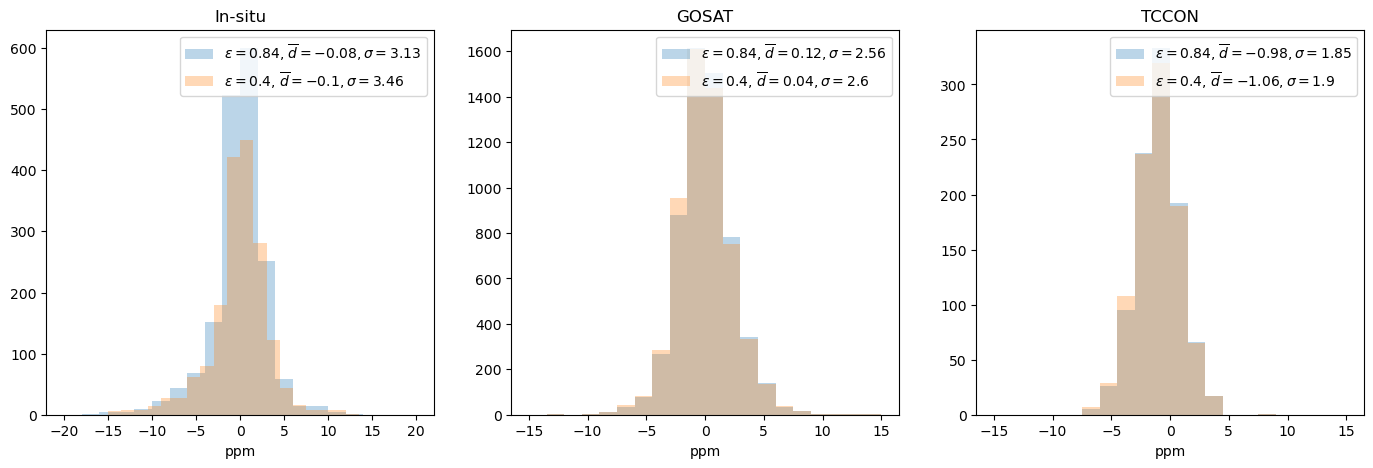

In [31]:
nbins=20
max_min=(-20,20)
fig,axs=plt.subplots(1,3,figsize=(17,5))

title=['In-situ', 'GOSAT','TCCON']
var=['posterior_diff']
label_0=['$K*x_{TM5} +y_{bg} -y_{meas}$','$K*x_{prior} +y_{bg} -y_{meas}$','$K*x_{posterior} +y_{bg} -y_{meas}$']
label_corr=['$\epsilon = 0.84$','$\epsilon = 0.4$']
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']

k=0
for corr in ['with', 'with_e04']:
    if False: #g_err==1 or g_err==2 or g_err==3:
        continue
    temp=inversion_TM5.data[corr].insitu
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_corr[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    axs[0].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[0].legend()
    axs[0].set_xlabel('ppm')
    axs[0].set_title(title[0])

    max_min=(-15,15)
    temp=inversion_TM5.data[corr].gosat
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_corr[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    axs[1].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[1].legend()
    axs[1].set_xlabel('ppm')
    axs[1].set_title(title[1])

    
    max_min=(-15,15)
    temp=inversion_TM5.data[corr].tccon
    d0=np.round(np.mean(temp.posterior_diff).compute().item(),2)
    d_abs=np.round(np.mean(np.abs(temp.posterior_diff)).compute().item(),2)
    d_std=np.round(np.std(temp.posterior_diff).compute().item(),2)
    label=fr'{label_corr[k]}, $\overline{{d}}={d0}, \sigma={d_std}$'
    axs[2].hist(temp.posterior_diff,alpha=0.3,color=default_colors[k], bins=nbins, range=max_min, label=label)
    axs[2].legend()
    axs[2].set_xlabel('ppm')
    axs[2].set_title(title[2])
    k+=1

plt.savefig(f'{savefig}/histogramm_with_e04vse084.png')